# Stacked Area Chart

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Stacks several series on top of each other over time. The top edge shows the total, and each band shows how much one component contributes.

## When to use

- Show how a total changes over time and which components drive it
- Show a few (2–6) parts with a meaningful sum (energy mix, revenue by segment)

## Avoid when

- Readers need precise values for the middle layers (only the bottom layer has a flat baseline)
- Components are not parts of a sum
- There are many layers or layers that cross a lot

## Alternatives

- Small-multiple area charts
- 100% stacked area (when shares matter more than totals)
- Line chart

## Design tips

- Put the most stable or most important layer at the bottom
- Label layers directly inside the bands
- Keep to 6 layers or fewer; fold the rest into 'Other'

## Example

Electricity generation mix (TWh) by source over 20 years, synthetic data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })

### Data

In [2]:
years = np.arange(2005, 2025)
t = years - 2005
df = pd.DataFrame({
    "Coal": 220 - 7.5 * t,
    "Gas": 110 + 3.0 * t,
    "Nuclear": np.full(len(t), 80.0) - 0.5 * t,
    "Wind": 2 + 0.25 * t ** 2,
    "Solar": 0.5 + 0.18 * t ** 2,
}, index=years).clip(lower=0)
df.tail()

,Coal,Gas,Nuclear,Wind,Solar
2020,107.5,155.0,72.5,58.25,41.00
2021,100.0,158.0,72.0,66.00,46.58
2022,92.5,161.0,71.5,74.25,52.52
2023,85.0,164.0,71.0,83.00,58.82
2024,77.5,167.0,70.5,92.25,65.48


### Plot

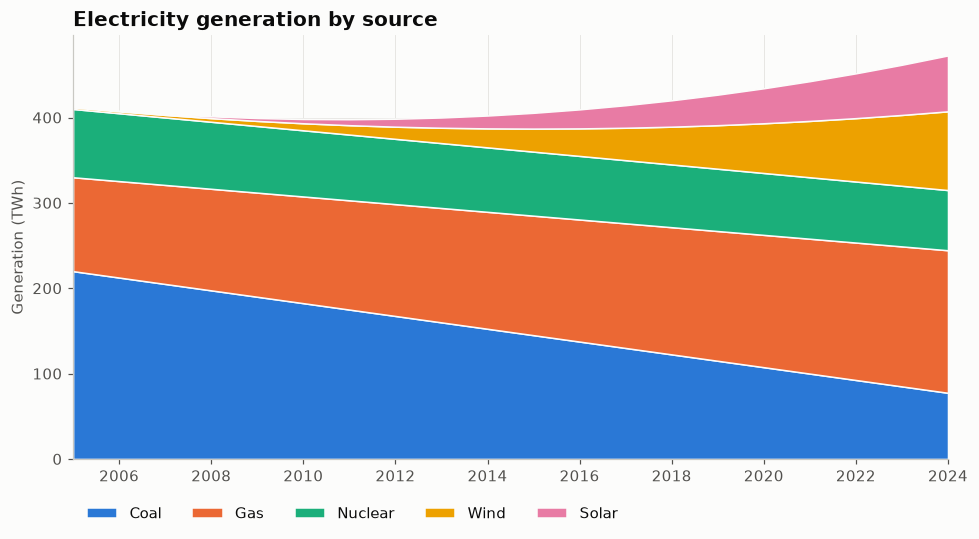

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.stackplot(df.index, df.T.values, labels=df.columns, colors=PALETTE[:5],
             edgecolor="#fcfcfb", linewidth=1)
ax.set_xlim(df.index[0], df.index[-1])
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_ylabel("Generation (TWh)")
ax.set_title("Electricity generation by source")
ax.legend(loc="upper left", ncol=5, bbox_to_anchor=(0, -0.08))
fig.tight_layout()
plt.show()

## How to read it

The top edge is total generation. Coal (the bottom band) shrinks while wind and solar (the top bands) grow, so the mix changes while the total stays roughly flat.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### altair

In [4]:
import altair as alt
long = df.rename_axis("year").reset_index().melt(id_vars="year", var_name="source", value_name="twh")
chart = alt.Chart(long).mark_area().encode(
    x=alt.X("year:O", title=None, axis=alt.Axis(labelAngle=0, values=list(range(2006, 2025, 2)))),
    y=alt.Y("twh:Q", stack="zero", title="Generation (TWh)"),
    color=alt.Color("source:N", sort=list(df.columns), title=None),
    order=alt.Order("order:Q"),
    tooltip=["year", "source", alt.Tooltip("twh:Q", format=".0f")],
).transform_calculate(order=f"indexof({list(df.columns)}, datum.source)"
).properties(title="Electricity generation by source", width=540, height=300)
chart

alt.Chart(...)

---
Standalone script: [`stacked_area.py`](stacked_area.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)